In [9]:
import pandas as pd
import numpy as np
import plotly.graph_objects as go
from pathlib import Path

In [6]:
# ==========================================================
# INPUT
# ==========================================================

INPUT_FILE = (
    "ARG_host_master.tsv"
)


# ==========================================================
# OUTPUT DIRECTORY
# ==========================================================

from pathlib import Path

OUTPUT_DIR = Path("Eskapee_sankey/")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)




In [7]:
# ==========================================================
# OUTPUT FILES
# ==========================================================

HTML_FILE = OUTPUT_DIR/"ARG_Class_Pathogen_Sankey.html"
PNG_FILE  = OUTPUT_DIR/"ARG_Class_Pathogen_Sankey.png"
PDF_FILE  = OUTPUT_DIR/"ARG_Class_Pathogen_Sankey.pdf"
EDGE_FILE = OUTPUT_DIR/"ARG_Class_Pathogen_Sankey_edges.tsv"


print("Input:")
print(INPUT_FILE)

print("\nOutput directory:")
print(OUTPUT_DIR)

Input:
ARG_host_master.tsv

Output directory:
Eskapee_sankey


In [32]:
df = pd.read_csv(
    INPUT_FILE,
    sep="\t",
    dtype=str
)

print("Initial rows:", f"{len(df):,}")

print("\nColumns:")
print(df.columns.tolist())

display(df.head())

Initial rows: 2,456

Columns:
['sample', 'read_id', 'ARG', 'ARG_class', 'taxon_level', 'taxon_name']


,sample,read_id,ARG,ARG_class,taxon_level,taxon_name
0,BH-242-30-Jan-2024,48a304fe-cf10-4c1a-b29d-813fccaebb24,ESCHERICHIA_COLI_MIPA,multidrug,S,Escherichia coli
1,BH-242-30-Jan-2024,19ceb80e-4e23-4918-b45d-a53b319f7a09,AADA,aminoglycoside,S,Klebsiella pneumoniae
2,BH-242-30-Jan-2024,410fd411-eb95-48f9-a883-1154c4c889bf,TOLC,multidrug,S,Enterobacter roggenkampii
3,BH-242-30-Jan-2024,77dd9a2d-b108-44f8-a2bd-0436e325d392,SUL1,sulfonamide,S,Klebsiella pneumoniae
4,BH-242-30-Jan-2024,3cf27a84-f9f5-4aa8-8786-471c7955d5fa,TETA,tetracycline,S,Klebsiella pneumoniae


In [33]:
# Strip whitespace
for col in [
    "sample",
    "read_id",
    "ARG",
    "ARG_class",
    "taxon_level",
    "taxon_name"
]:
    df[col] = df[col].astype(str).str.strip()


# Remove missing values
df = df[
    df["ARG"].notna() &
    df["ARG_class"].notna() &
    df["taxon_name"].notna()
].copy()


# Remove empty / NA-like values
df = df[
    ~df["ARG"].str.lower().isin(["", "nan", "none", "na"]) &
    ~df["ARG_class"].str.lower().isin(["", "nan", "none", "na"]) &
    ~df["taxon_name"].str.lower().isin(["", "nan", "none", "na"])
].copy()


# Remove Unclassified ARG classes
df = df[
    df["ARG_class"].str.lower() != "unclassified"
].copy()


print("Rows after cleaning:", f"{len(df):,}")

Rows after cleaning: 2,456


In [34]:
def assign_pathogen(taxon):

    taxon = str(taxon).strip().lower()

    if taxon.startswith("escherichia coli"):
        return "Escherichia coli"

    elif taxon.startswith("klebsiella pneumoniae"):
        return "Klebsiella pneumoniae"

    elif taxon.startswith("enterobacter"):
        return "Enterobacter spp."

    elif taxon.startswith("pseudomonas aeruginosa"):
        return "Pseudomonas aeruginosa"

    elif taxon.startswith("acinetobacter baumannii"):
        return "Acinetobacter baumannii"

    elif taxon.startswith("enterococcus faecium"):
        return "Enterococcus faecium"

    elif taxon.startswith("staphylococcus aureus"):
        return "Staphylococcus aureus"

    else:
        return np.nan


df["Pathogen"] = df["taxon_name"].apply(
    assign_pathogen
)


# Keep only the seven target pathogens
df = df.dropna(
    subset=["Pathogen"]
).copy()


print("Rows after pathogen filtering:", f"{len(df):,}")

display(
    df["Pathogen"]
      .value_counts()
      .to_frame("Read_Count")
)

Rows after pathogen filtering: 2,456


,Read_Count
Pathogen,
Escherichia coli,1064
Klebsiella pneumoniae,665
Enterobacter spp.,328
Pseudomonas aeruginosa,276
Acinetobacter baumannii,90
Enterococcus faecium,20
Staphylococcus aureus,13


In [35]:
PATHOGEN_ORDER = [
    "Escherichia coli",
    "Klebsiella pneumoniae",
    "Enterobacter spp.",
    "Pseudomonas aeruginosa",
    "Acinetobacter baumannii",
    "Enterococcus faecium",
    "Staphylococcus aureus"
]


# Keep only those actually present
PATHOGEN_ORDER = [
    p for p in PATHOGEN_ORDER
    if p in df["Pathogen"].unique()
]


print("Pathogen order:")
for i, pathogen in enumerate(PATHOGEN_ORDER, 1):

    count = (
        df["Pathogen"] == pathogen
    ).sum()

    print(
        f"{i}. {pathogen:<30} {count:,}"
    )

Pathogen order:
1. Escherichia coli               1,064
2. Klebsiella pneumoniae          665
3. Enterobacter spp.              328
4. Pseudomonas aeruginosa         276
5. Acinetobacter baumannii        90
6. Enterococcus faecium           20
7. Staphylococcus aureus          13


In [36]:
arg_class_counts = (
    df.groupby("ARG_class")
      .size()
      .sort_values(
          ascending=False
      )
)

ARG_CLASS_ORDER = (
    arg_class_counts.index.tolist()
)


print(
    "Number of ARG classes:",
    len(ARG_CLASS_ORDER)
)

display(
    arg_class_counts
      .rename("Read_Count")
      .to_frame()
)

Number of ARG classes: 17


,Read_Count
ARG_class,
aminoglycoside,529
multidrug,466
sulfonamide,399
beta-lactam,316
MLS,258
tetracycline,167
phenicol,68
peptide,58
diaminopyrimidine,54


In [37]:
arg_counts = (
    df.groupby(
        ["ARG_class", "ARG"]
    )
    .size()
    .reset_index(
        name="Count"
    )
)


display(
    arg_counts
      .sort_values(
          "Count",
          ascending=False
      )
      .head(20)
)

,ARG_class,ARG,Count
156,sulfonamide,SUL1,336
54,beta-lactam,OXA,203
24,aminoglycoside,AADA,179
159,tetracycline,TETA,134
34,aminoglycoside,APH(6)-I,108
31,aminoglycoside,APH(3'')-I,96
157,sulfonamide,SUL2,63
12,MLS,MRX,55
14,MLS,MSRE,50
9,MLS,MPHA,50


In [38]:
TOP_N = 2


top_args_by_class = {}

for arg_class in ARG_CLASS_ORDER:

    temp = arg_counts[
        arg_counts["ARG_class"] == arg_class
    ].copy()

    temp = temp.sort_values(
        "Count",
        ascending=False
    )

    top_args = (
        temp["ARG"]
        .head(TOP_N)
        .tolist()
    )

    top_args_by_class[arg_class] = top_args


# Display the selected ARGs
print("=" * 70)
print("TOP 2 ARGs PER ARG CLASS")
print("=" * 70)

for arg_class in ARG_CLASS_ORDER:

    print(
        f"\n{arg_class}"
    )

    for arg in top_args_by_class[arg_class]:

        count = arg_counts.loc[
            (arg_counts["ARG_class"] == arg_class) &
            (arg_counts["ARG"] == arg),
            "Count"
        ].iloc[0]

        print(
            f"   {arg:<30} {count:,}"
        )

TOP 2 ARGs PER ARG CLASS

aminoglycoside
   AADA                           179
   APH(6)-I                       108

multidrug
   OMPR                           37
   EMRD                           32

sulfonamide
   SUL1                           336
   SUL2                           63

beta-lactam
   OXA                            203
   VEB-1                          27

MLS
   MRX                            55
   MPHA                           50

tetracycline
   TETA                           134
   TET34                          7

phenicol
   CMLA                           35
   CATB                           23

peptide
   UGD                            30
   EPTA                           12

diaminopyrimidine
   DFRA14                         14
   DFRB1                          12

fluoroquinolone
   PATA                           19
   MDTK                           16

rifamycin
   ADP-RIBOSYLATING_TRANSFERASE_ARR 24

bacitracin
   BACA                           21

fosm

In [39]:
def collapse_arg(row):

    arg_class = row["ARG_class"]
    arg = row["ARG"]

    top_args = top_args_by_class.get(
        arg_class,
        []
    )

    if arg in top_args:
        return arg

    return "Other ARGs"


df["ARG_display"] = df.apply(
    collapse_arg,
    axis=1
)


print(
    "Unique displayed ARG categories:",
    df["ARG_display"].nunique()
)

Unique displayed ARG categories: 30


In [40]:
class_arg = (
    df.groupby(
        ["ARG_class", "ARG_display"]
    )
    .size()
    .reset_index(
        name="Count"
    )
)


display(
    class_arg.head(20)
)

,ARG_class,ARG_display,Count
0,MLS,MPHA,50
1,MLS,MRX,55
2,MLS,Other ARGs,153
3,aminoglycoside,AADA,179
4,aminoglycoside,APH(6)-I,108
5,aminoglycoside,Other ARGs,242
6,aminoglycoside:aminocoumarin,CPXA,18
7,bacitracin,BACA,21
8,beta-lactam,OXA,203
9,beta-lactam,Other ARGs,86


In [41]:
pathogen_class = (
    df.groupby(
        ["Pathogen", "ARG_class"]
    )
    .size()
    .reset_index(
        name="Count"
    )
)


display(
    pathogen_class.head(20)
)

,Pathogen,ARG_class,Count
0,Acinetobacter baumannii,MLS,10
1,Acinetobacter baumannii,aminoglycoside,25
2,Acinetobacter baumannii,beta-lactam,13
3,Acinetobacter baumannii,fosmidomycin,1
4,Acinetobacter baumannii,multidrug,20
5,Acinetobacter baumannii,sulfonamide,14
6,Acinetobacter baumannii,tetracycline,7
7,Enterobacter spp.,MLS,15
8,Enterobacter spp.,aminoglycoside,36
9,Enterobacter spp.,aminoglycoside:aminocoumarin,8


In [42]:
ARG_ORDER = []

ARG_ORDER_BY_CLASS = {}


for arg_class in ARG_CLASS_ORDER:

    temp = class_arg[
        class_arg["ARG_class"] == arg_class
    ].copy()

    # Sort by abundance
    temp = temp.sort_values(
        "Count",
        ascending=False
    )

    # Top actual ARGs
    actual_args = [
        x for x in temp["ARG_display"]
        if x != "Other ARGs"
    ]

    actual_args = actual_args[:TOP_N]

    ordered = actual_args.copy()

    # Add Other ARGs at the end if present
    if "Other ARGs" in temp["ARG_display"].values:
        ordered.append("Other ARGs")

    ARG_ORDER_BY_CLASS[arg_class] = ordered

    ARG_ORDER.extend(
        ordered
    )


print(
    "Total ARG nodes:",
    len(ARG_ORDER)
)

print(
    "Maximum possible:",
    len(ARG_CLASS_ORDER) * 3
)

Total ARG nodes: 38
Maximum possible: 51


In [43]:
print("=" * 70)
print("FINAL ARG STRUCTURE")
print("=" * 70)

for arg_class in ARG_CLASS_ORDER:

    print(
        f"\n{arg_class}"
    )

    for arg in ARG_ORDER_BY_CLASS[arg_class]:

        count = class_arg.loc[
            (class_arg["ARG_class"] == arg_class) &
            (class_arg["ARG_display"] == arg),
            "Count"
        ].iloc[0]

        print(
            f"   {arg:<30} {count:,}"
        )

FINAL ARG STRUCTURE

aminoglycoside
   AADA                           179
   APH(6)-I                       108
   Other ARGs                     242

multidrug
   OMPR                           37
   EMRD                           32
   Other ARGs                     397

sulfonamide
   SUL1                           336
   SUL2                           63

beta-lactam
   OXA                            203
   VEB-1                          27
   Other ARGs                     86

MLS
   MRX                            55
   MPHA                           50
   Other ARGs                     153

tetracycline
   TETA                           134
   TET34                          7
   Other ARGs                     26

phenicol
   CMLA                           35
   CATB                           23
   Other ARGs                     10

peptide
   UGD                            30
   EPTA                           12
   Other ARGs                     16

diaminopyrimidine
   DFRA14   

In [60]:
# ==========================================================
# ARG NODES
# ==========================================================

ARG_START = 0

arg_nodes = {}

for i, arg_class in enumerate(ARG_CLASS_ORDER):

    for arg in ARG_ORDER_BY_CLASS[arg_class]:

        # Internal node ID
        internal_id = (
            f"{arg_class}__{arg}"
        )

        arg_nodes[(
            arg_class,
            arg
        )] = ARG_START + len(arg_nodes)


# ==========================================================
# ARG CLASS NODES
# ==========================================================

CLASS_START = len(arg_nodes)

arg_class_nodes = {
    arg_class: CLASS_START + i
    for i, arg_class in enumerate(
        ARG_CLASS_ORDER
    )
}


# ==========================================================
# PATHOGEN NODES
# ==========================================================

PATHOGEN_START = (
    CLASS_START +
    len(ARG_CLASS_ORDER)
)

pathogen_nodes = {
    pathogen: PATHOGEN_START + i
    for i, pathogen in enumerate(
        PATHOGEN_ORDER
    )
}


print("ARG nodes:", len(arg_nodes))
print("ARG class nodes:", len(arg_class_nodes))
print("Pathogen nodes:", len(pathogen_nodes))

ARG nodes: 38
ARG class nodes: 17
Pathogen nodes: 7


In [123]:
labels = []

ARG_LABELS = []


for arg_class in ARG_CLASS_ORDER:

    for arg in ARG_ORDER_BY_CLASS[arg_class]:

        ARG_LABELS.append(
            arg
        )


labels = (
    ARG_LABELS +
    ARG_CLASS_ORDER +
    PATHOGEN_ORDER
)


print(
    "Total Sankey nodes:",
    len(labels)
)

Total Sankey nodes: 62


In [62]:
import colorsys

In [63]:
# ==========================================================
# COLOR FUNCTIONS
# ==========================================================

def generate_distinct_colors(n, saturation=0.65, lightness=0.50):

    colors = []

    for i in range(n):

        hue = i / max(n, 1)

        r, g, b = colorsys.hls_to_rgb(
            hue,
            lightness,
            saturation
        )

        colors.append(
            "#{:02x}{:02x}{:02x}".format(
                int(r * 255),
                int(g * 255),
                int(b * 255)
            )
        )

    return colors


def hex_to_rgba(hex_color, alpha=0.55):

    hex_color = hex_color.lstrip("#")

    r = int(hex_color[0:2], 16)
    g = int(hex_color[2:4], 16)
    b = int(hex_color[4:6], 16)

    return (
        f"rgba({r},{g},{b},{alpha})"
    )


# ==========================================================
# ARG CLASS COLORS
# ==========================================================

class_colors_list = generate_distinct_colors(
    len(ARG_CLASS_ORDER),
    saturation=0.65,
    lightness=0.48
)

ARG_CLASS_COLORS = {
    arg_class: color
    for arg_class, color in zip(
        ARG_CLASS_ORDER,
        class_colors_list
    )
}


# ==========================================================
# ARG COLORS
# ==========================================================

# Only actual top ARGs need their own colors
actual_args = []

for arg_class in ARG_CLASS_ORDER:

    for arg in ARG_ORDER_BY_CLASS[arg_class]:

        if arg != "Other ARGs":
            actual_args.append(
                (arg_class, arg)
            )


arg_colors_list = generate_distinct_colors(
    len(actual_args),
    saturation=0.60,
    lightness=0.50
)


ARG_COLORS = {
    key: color
    for key, color in zip(
        actual_args,
        arg_colors_list
    )
}


# Other ARGs use the corresponding ARG-class color
for arg_class in ARG_CLASS_ORDER:

    ARG_COLORS[
        (arg_class, "Other ARGs")
    ] = ARG_CLASS_COLORS[arg_class]


print(
    "ARG class colors:",
    len(ARG_CLASS_COLORS)
)

print(
    "ARG colors:",
    len(ARG_COLORS)
)

ARG class colors: 17
ARG colors: 46


In [101]:
print("ARG CLASS COLORS")
print("=" * 50)

for arg_class in ARG_CLASS_ORDER:

    print(
        f"{arg_class:<30} "
        f"{ARG_CLASS_COLORS[arg_class]}"
    )


print("\n\nARG COLORS")
print("=" * 50)

for key, color in ARG_COLORS.items():

    print(
        f"{key[0]:<25} "
        f"{key[1]:<25} "
        f"{color}"
    )

ARG CLASS COLORS
aminoglycoside                 #c92a2a
multidrug                      #c9632a
sulfonamide                    #c99b2a
beta-lactam                    #c0c92a
MLS                            #88c92a
tetracycline                   #50c92a
phenicol                       #2ac93d
peptide                        #2ac975
diaminopyrimidine              #2ac9ad
fluoroquinolone                #2aadc9
rifamycin                      #2a75c9
bacitracin                     #2a3dc9
fosmidomycin                   #502ac9
aminoglycoside:aminocoumarin   #882ac9
fosfomycin                     #c02ac9
glycopeptide                   #c92a9b
nucleoside                     #c92a62


ARG COLORS
aminoglycoside            AADA                      #cc3232
aminoglycoside            APH(6)-I                  #cc5232
multidrug                 OMPR                      #cc7232
multidrug                 EMRD                      #cc9132
sulfonamide               SUL1                      #ccb132
sulfona

In [124]:
# ==========================================================
# COLOR FUNCTIONS
# ==========================================================

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors


def hex_to_rgba(hex_color, alpha=0.55):

    hex_color = hex_color.lstrip("#")

    r = int(hex_color[0:2], 16)
    g = int(hex_color[2:4], 16)
    b = int(hex_color[4:6], 16)

    return f"rgba({r},{g},{b},{alpha})"


def lighten_color(hex_color, amount=0.35):
    """
    Lighten a color by blending it with white.
    amount = 0   -> original color
    amount = 1   -> white
    """

    rgb = np.array(
        mcolors.to_rgb(hex_color)
    )

    white = np.array(
        [1, 1, 1]
    )

    new_rgb = (
        rgb * (1 - amount)
        + white * amount
    )

    return mcolors.to_hex(
        new_rgb
    )


def darken_color(hex_color, amount=0.25):
    """
    Darken a color.
    amount = 0   -> original color
    amount = 1   -> black
    """

    rgb = np.array(
        mcolors.to_rgb(hex_color)
    )

    new_rgb = rgb * (1 - amount)

    return mcolors.to_hex(
        new_rgb
    )


# ==========================================================
# TAB20 BASE PALETTE
# ==========================================================

tab20_rgb = plt.cm.tab20.colors

TAB20_COLORS = [
    mcolors.to_hex(color)
    for color in tab20_rgb
]


print(
    "Available Tab20 colors:",
    len(TAB20_COLORS)
)


# ==========================================================
# ARG CLASS COLORS
# ==========================================================
#
# 17 ARG classes
# → 17 different Tab20 base colors
#
# These colors represent the ARG classes on the
# ARG-class → pathogen side of the Sankey.
# ==========================================================

ARG_CLASS_COLORS = {
    arg_class: TAB20_COLORS[i]
    for i, arg_class in enumerate(
        ARG_CLASS_ORDER
    )
}


# ==========================================================
# ARG COLORS
# ==========================================================
#
# Each ARG class:
#
#     ARG 1 → darker shade
#     ARG 2 → lighter shade
#     Other → base class color
#
# This makes the two ARGs visually related to their
# parent ARG class.
# ==========================================================

ARG_COLORS = {}


for arg_class in ARG_CLASS_ORDER:

    # Base class color
    base_color = ARG_CLASS_COLORS[
        arg_class
    ]


    # ------------------------------------------------------
    # Get the ARGs belonging to this class
    # ------------------------------------------------------

    args_in_class = [
        arg
        for arg in ARG_ORDER_BY_CLASS[arg_class]
        if arg != "Other ARGs"
    ]


    # ------------------------------------------------------
    # Top ARG 1
    # ------------------------------------------------------

    if len(args_in_class) >= 1:

        ARG_COLORS[
            (arg_class, args_in_class[0])
        ] = darken_color(
            base_color,
            amount=0.20
        )


    # ------------------------------------------------------
    # Top ARG 2
    # ------------------------------------------------------

    if len(args_in_class) >= 2:

        ARG_COLORS[
            (arg_class, args_in_class[1])
        ] = lighten_color(
            base_color,
            amount=0.30
        )


    # ------------------------------------------------------
    # Other ARGs
    # ------------------------------------------------------
    #
    # Other ARGs use the original ARG-class color.
    # ------------------------------------------------------

    if "Other ARGs" in ARG_ORDER_BY_CLASS[arg_class]:

        ARG_COLORS[
            (arg_class, "Other ARGs")
        ] = base_color


# ==========================================================
# PRINT ARG CLASS COLORS
# ==========================================================

print("\n")
print("=" * 70)
print("ARG CLASS COLORS")
print("=" * 70)

for arg_class in ARG_CLASS_ORDER:

    print(
        f"{arg_class:<30}"
        f"{ARG_CLASS_COLORS[arg_class]}"
    )


# ==========================================================
# PRINT ARG COLORS
# ==========================================================

print("\n")
print("=" * 70)
print("ARG COLORS")
print("=" * 70)

for arg_class in ARG_CLASS_ORDER:

    print(
        f"\n{arg_class}"
    )

    for arg in ARG_ORDER_BY_CLASS[arg_class]:

        color = ARG_COLORS[
            (arg_class, arg)
        ]

        print(
            f"   {arg:<30}"
            f"{color}"
        )


print("\n")
print(
    "ARG class colors:",
    len(ARG_CLASS_COLORS)
)

print(
    "ARG colors:",
    len(ARG_COLORS)
)

Available Tab20 colors: 20


ARG CLASS COLORS
aminoglycoside                #1f77b4
multidrug                     #aec7e8
sulfonamide                   #ff7f0e
beta-lactam                   #ffbb78
MLS                           #2ca02c
tetracycline                  #98df8a
phenicol                      #d62728
peptide                       #ff9896
diaminopyrimidine             #9467bd
fluoroquinolone               #c5b0d5
rifamycin                     #8c564b
bacitracin                    #c49c94
fosmidomycin                  #e377c2
aminoglycoside:aminocoumarin  #f7b6d2
fosfomycin                    #7f7f7f
glycopeptide                  #c7c7c7
nucleoside                    #bcbd22


ARG COLORS

aminoglycoside
   AADA                          #195f90
   APH(6)-I                      #62a0cb
   Other ARGs                    #1f77b4

multidrug
   OMPR                          #8b9fba
   EMRD                          #c6d8ef
   Other ARGs                    #aec7e8

sulfonamide
   SUL1  

In [134]:
node_colors = []


# ==========================================================
# ARG NODE COLORS
# ==========================================================

for arg_class in ARG_CLASS_ORDER:

    for arg in ARG_ORDER_BY_CLASS[arg_class]:

        node_colors.append(
            ARG_COLORS[
                (arg_class, arg)
            ]
        )


# ==========================================================
# ARG CLASS NODE COLORS
# ==========================================================

for arg_class in ARG_CLASS_ORDER:

    node_colors.append(
        ARG_CLASS_COLORS[arg_class]
    )


# ==========================================================
# PATHOGEN NODE COLORS
# ==========================================================

# Neutral colors for pathogens
pathogen_colors = [
    "#444444",
    "#555555",
    "#666666",
    "#777777",
    "#888888",
    "#999999",
    "#AAAAAA"
]


for i, pathogen in enumerate(
    PATHOGEN_ORDER
):

    node_colors.append(
        pathogen_colors[i]
    )


print(
    "Node colors:",
    len(node_colors)
)

Node colors: 62


In [135]:
sources = []
targets = []
values = []
link_colors = []


# ==========================================================
# ARG → ARG CLASS
# ==========================================================

for _, row in class_arg.iterrows():

    arg_class = row["ARG_class"]
    arg = row["ARG_display"]
    count = row["Count"]

    # Source
    sources.append(
        arg_nodes[
            (arg_class, arg)
        ]
    )

    # Target
    targets.append(
        arg_class_nodes[arg_class]
    )

    # Flow width
    values.append(
        count
    )

    # IMPORTANT:
    # Link gets the ARG color
    arg_color = ARG_COLORS[
        (arg_class, arg)
    ]

    link_colors.append(
        hex_to_rgba(
            arg_color,
            alpha=0.55
        )
    )


# ==========================================================
# ARG CLASS → PATHOGEN
# ==========================================================

for _, row in pathogen_class.iterrows():

    arg_class = row["ARG_class"]
    pathogen = row["Pathogen"]
    count = row["Count"]

    # Source
    sources.append(
        arg_class_nodes[arg_class]
    )

    # Target
    targets.append(
        pathogen_nodes[pathogen]
    )

    # Flow width
    values.append(
        count
    )

    # IMPORTANT:
    # Link gets ARG CLASS color
    class_color = ARG_CLASS_COLORS[
        arg_class
    ]

    link_colors.append(
        hex_to_rgba(
            class_color,
            alpha=0.55
        )
    )


print(
    "Total links:",
    len(sources)
)

print(
    "Total link colors:",
    len(link_colors)
)

Total links: 109
Total link colors: 109


In [136]:
# ==========================================================
# X POSITION
# ==========================================================

node_x = []


# ARGs — left
node_x.extend(
    [0.01] * len(ARG_LABELS)
)


# ARG classes — middle
node_x.extend(
    [0.50] * len(ARG_CLASS_ORDER)
)


# Pathogens — right
node_x.extend(
    [0.99] * len(PATHOGEN_ORDER)
)

In [142]:
node_y = []


# ==========================================================
# ARG Y POSITIONS
# ==========================================================

n_args = len(ARG_LABELS)

arg_y = np.linspace(
    0.005,
    0.995,
    n_args
)

node_y.extend(
    arg_y.tolist()
)


# ==========================================================
# ARG CLASS Y POSITIONS
# ==========================================================

n_classes = len(ARG_CLASS_ORDER)

class_y = np.linspace(
    0.03,
    0.97,
    n_classes
)

node_y.extend(
    class_y.tolist()
)


# ==========================================================
# PATHOGEN Y POSITIONS
# ==========================================================

# ==========================================================
# PATHOGEN Y POSITIONS
# ==========================================================

pathogen_y = np.linspace(
    0.08,
    0.92,
    len(PATHOGEN_ORDER)
)

node_y.extend(
    pathogen_y.tolist()
)

print(
    "Number of Y positions:",
    len(node_y)
)

Number of Y positions: 62


In [148]:
fig = go.Figure(
    go.Sankey(

        # Fixed arrangement keeps the three columns
        # exactly where we want them
        arrangement="fixed",

        node=dict(

            label=labels,

            x=node_x,

            y=node_y,

            pad=25,

            thickness=18,

            color=node_colors,

            line=dict(
                color="rgba(0,0,0,0.6)",
                width=0.5
            ),

            hovertemplate=(
                "<b>%{label}</b>"
                "<extra></extra>"
            )
        ),

        link=dict(

            source=sources,

            target=targets,

            value=values,

            color=link_colors,

            hovertemplate=(
                "<b>%{source.label}</b>"
                " → "
                "<b>%{target.label}</b>"
                "<br>"
                "Read associations: %{value:,}"
                "<extra></extra>"
            )
        )
    )
)

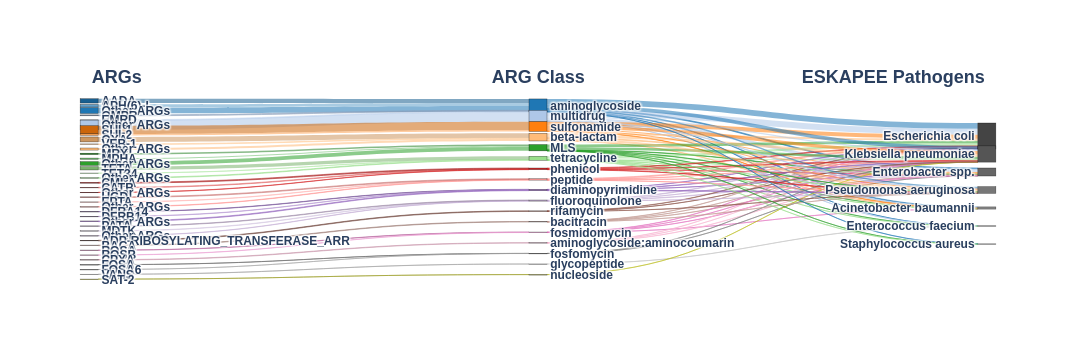

In [139]:
fig.add_annotation(

    x=0.01,
    y=1.2,

    xref="paper",
    yref="paper",

    text="<b>ARGs</b>",

    showarrow=False,

    xanchor="left",

    font=dict(
        size=18
    )
)


fig.add_annotation(

    x=0.50,
    y=1.2,

    xref="paper",
    yref="paper",

    text="<b>ARG Class</b>",

    showarrow=False,

    xanchor="center",

    font=dict(
        size=18
    )
)


fig.add_annotation(

    x=0.99,
    y=1.2,

    xref="paper",
    yref="paper",

    text="<b>ESKAPEE Pathogens</b>",

    showarrow=False,

    xanchor="right",

    font=dict(
        size=18
    )
)

In [150]:
fig.write_html(
    str(HTML_FILE),
    include_plotlyjs=True
)

print(
    "Interactive Sankey saved:"
)

print(
    HTML_FILE
)

Interactive Sankey saved:
Eskapee_sankey/ARG_Class_Pathogen_Sankey.html


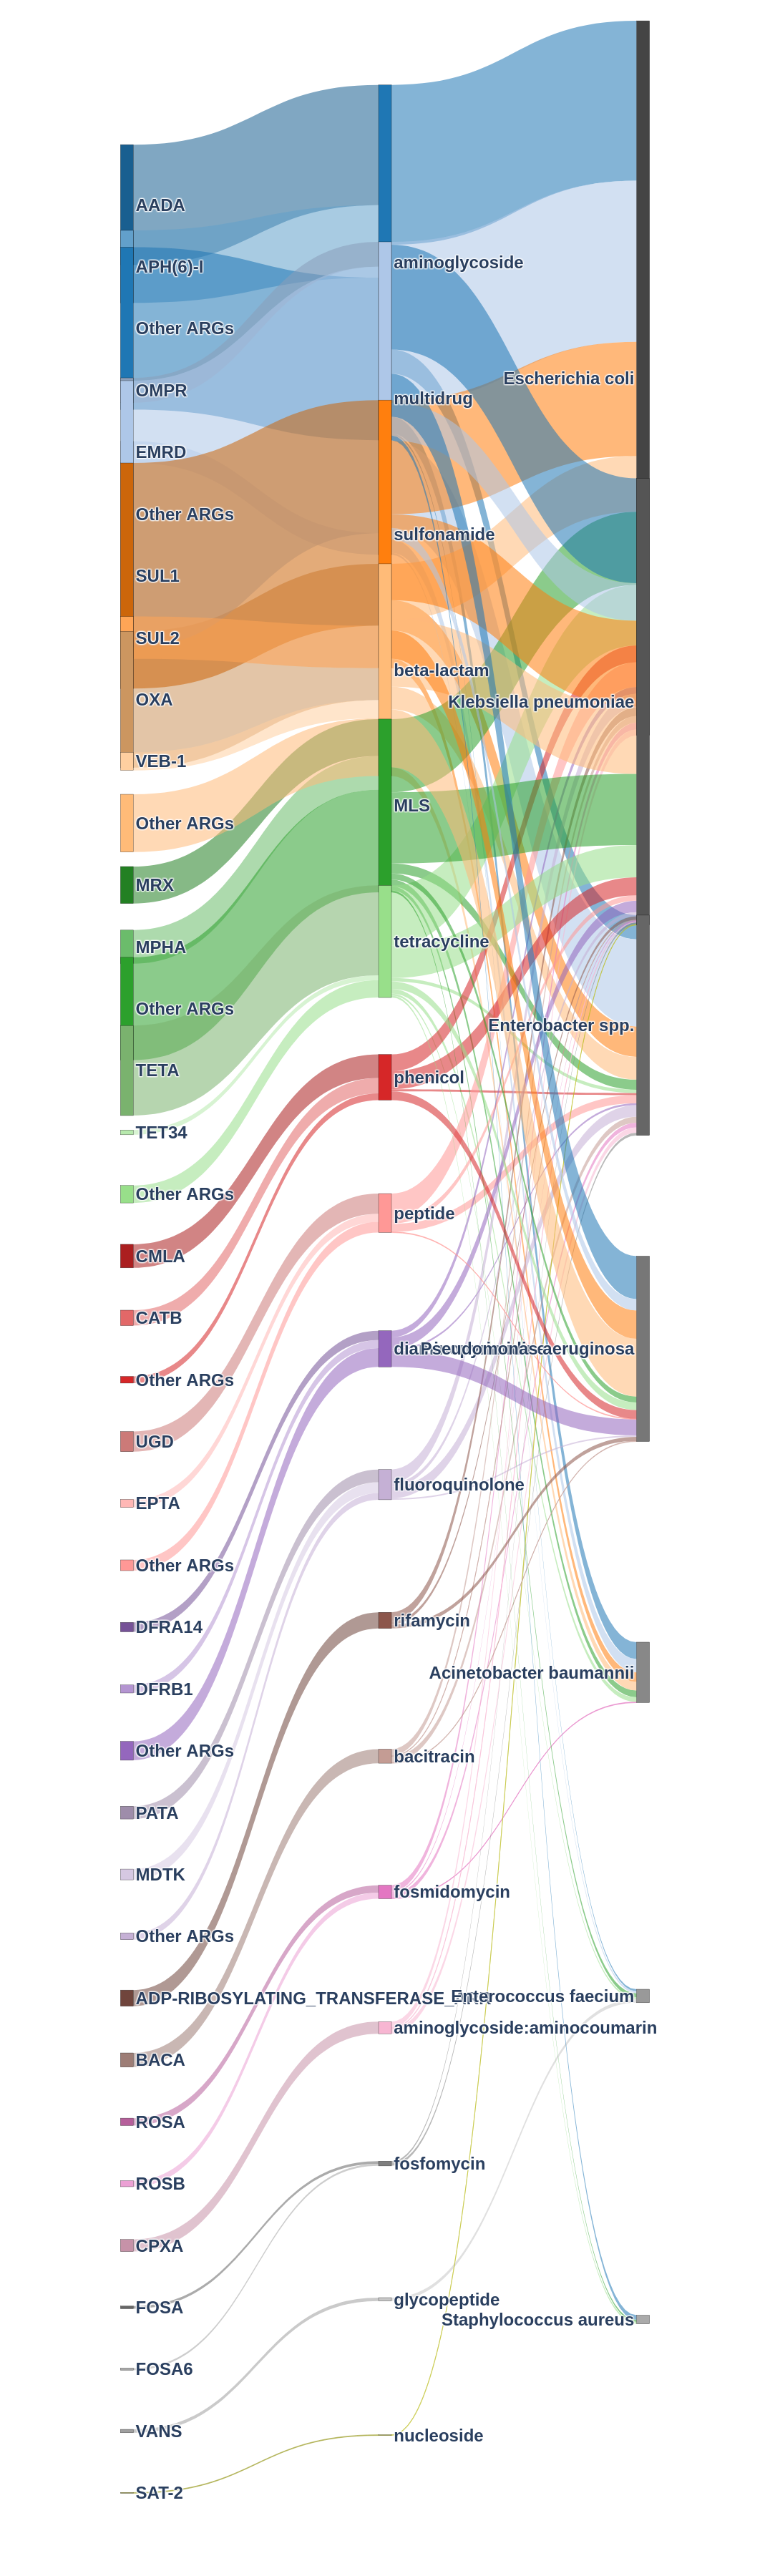

In [149]:
# Make all Sankey labels bold
labels = [f"<b>{label}</b>" for label in labels]

fig.update_layout(
    width=2200,
    height=3600,

    margin=dict(
        l=170,
        r=170,
        t=270,
        b=100
    ),

    font=dict(
        family="Arial",
        size=24
    ),

    paper_bgcolor="white",
    plot_bgcolor="white"
)

fig.show()

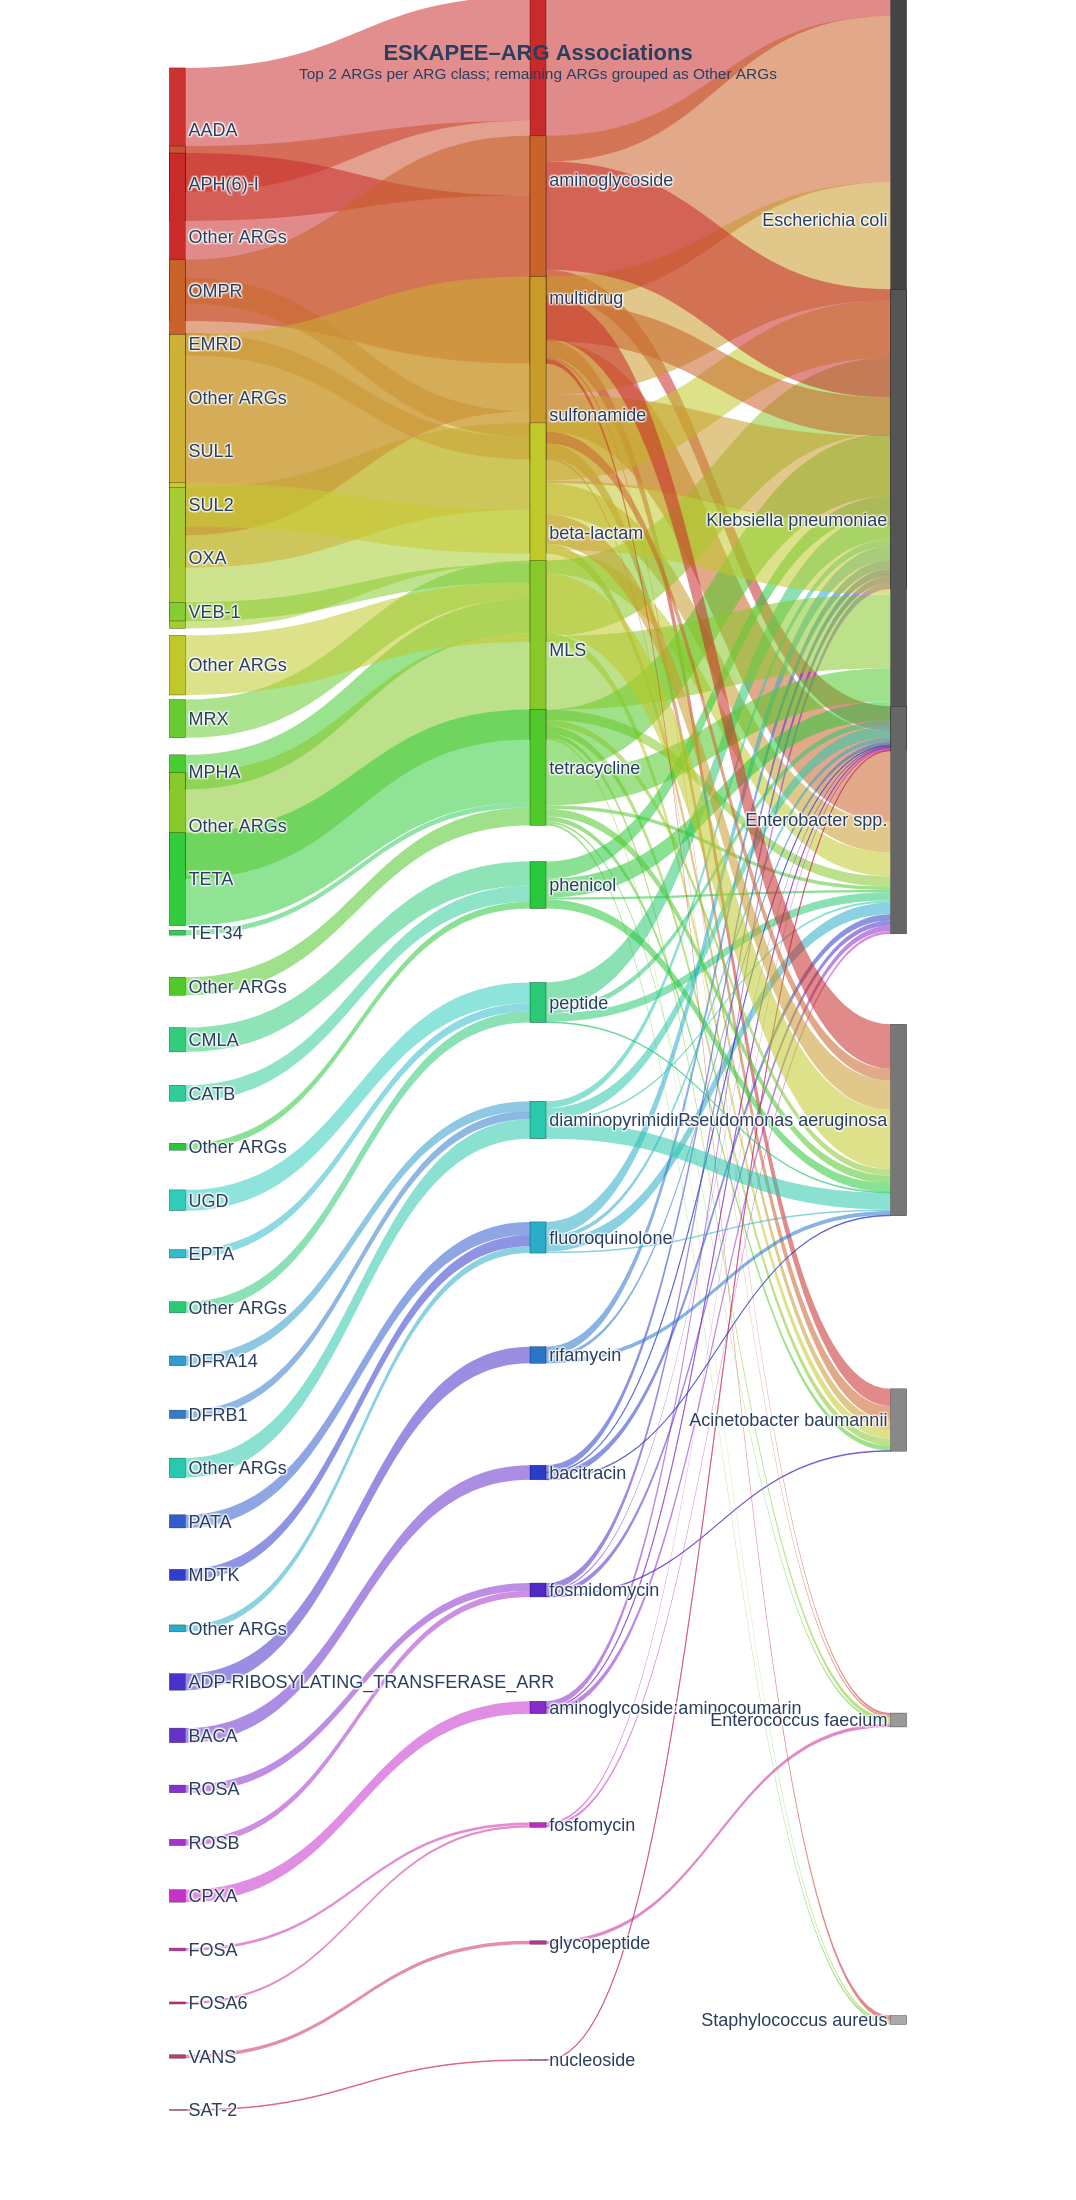

In [89]:
fig.update_layout(

    width=1100,

    height=2200,

    margin=dict(
        l=170,
        r=170,
        t=120,
        b=80
    ),

    font=dict(
        family="Arial",
        size=18
    ),

    paper_bgcolor="white",

    plot_bgcolor="white"
)


fig.show()

In [100]:
fig.write_html(
    str(HTML_FILE),
    include_plotlyjs=True
)

print(
    "Interactive Sankey saved:"
)

print(
    HTML_FILE
)

Interactive Sankey saved:
Eskapee_sankey/ARG_Class_Pathogen_Sankey.html
